# 6.1 PINN：原理与实现 —— 实验

本 Notebook 与 `A1-G12-正文.md` 的 6.1 节一一对应。所有数值均为本 Notebook 实际运行输出；解析解与有限差分是独立参考，训练点与评价点分开。

In [1]:
%matplotlib inline
import json, math, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FIG_DIR = Path("图片")
assert FIG_DIR.is_dir(), "缺少 图片/ 目录；请在提交包根目录启动 Jupyter"
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 160
plt.rcParams["axes.grid"] = True
PI = math.pi

print("Python:", __import__("platform").python_version())
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Python: 3.12.10
PyTorch: 2.6.0+cu124
NumPy: 1.26.4
Matplotlib: 3.8.3
Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. 开场反例：方程答对了，边界呢？

取
$$-u''=\pi^2\sin(\pi x),\quad x\in(0,1),\qquad u(0)=u(1)=0,$$
精确解 $u^*(x)=\sin(\pi x)$。候选解
$$v(x)=\sin(\pi x)+3x+2$$
满足 $-v''=\pi^2\sin(\pi x)$，但 $v(0)=2$、$v(1)=5$。先预测：内部残差应为零，边界损失为 $(2^2+5^2)/2=14.5$，相对 $L^2$ 误差为 $\sqrt{26}\approx5.10$。

In [2]:
x_c = torch.linspace(0.0, 1.0, 2001, dtype=torch.float64).reshape(-1, 1)
x_c.requires_grad_(True)
v = torch.sin(PI * x_c) + 3.0 * x_c + 2.0
v_x = torch.autograd.grad(v, x_c, grad_outputs=torch.ones_like(v), create_graph=True)[0]
v_xx = torch.autograd.grad(v_x, x_c, grad_outputs=torch.ones_like(v_x), create_graph=False)[0]
u_star_c = torch.sin(PI * x_c)
f_c = PI ** 2 * torch.sin(PI * x_c)
r_c = -v_xx - f_c
Lb_c = (v[0, 0] ** 2 + v[-1, 0] ** 2) / 2.0
err_c = v - u_star_c
rel_c = float(torch.linalg.norm(err_c) / torch.linalg.norm(u_star_c))

print("max |interior residual| =", float(r_c.abs().max()))
print("v(0), v(1)             =", float(v[0, 0]), float(v[-1, 0]))
print("boundary loss L_b      =", float(Lb_c))
print("relative L2 (2001-pt grid) =", rel_c)
print("analytic relative L2       =", math.sqrt(26.0))
print("sqrt(26)               =", math.sqrt(26.0))

assert float(r_c.abs().max()) < 1e-12
assert abs(float(v[0, 0]) - 2.0) < 1e-12 and abs(float(v[-1, 0]) - 5.0) < 1e-12
assert abs(float(Lb_c) - 14.5) < 1e-12
assert abs(rel_c - math.sqrt(26.0)) < 2e-3
print("PASS: 反例的解析值核对通过")


max |interior residual| = 1.7763568394002505e-15
v(0), v(1)             = 2.0 5.0
boundary loss L_b      = 14.5
relative L2 (2001-pt grid) = 5.100441230913262
analytic relative L2       = 5.0990195135927845
sqrt(26)               = 5.0990195135927845
PASS: 反例的解析值核对通过


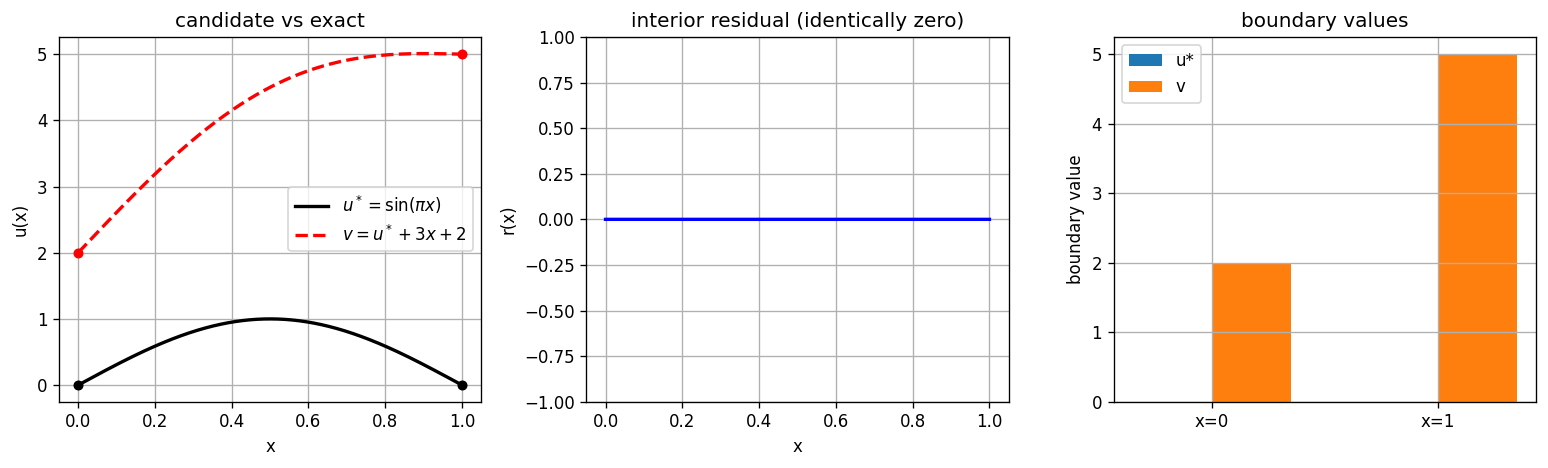

In [3]:
x_np = x_c.detach().cpu().numpy().ravel()
v_np = v.detach().cpu().numpy().ravel()
u_np = u_star_c.detach().cpu().numpy().ravel()
r_np = r_c.detach().cpu().numpy().ravel()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].plot(x_np, u_np, "k-", lw=2, label=r"$u^*=\sin(\pi x)$")
axes[0].plot(x_np, v_np, "r--", lw=2, label=r"$v=u^*+3x+2$")
axes[0].plot([0, 1], [0, 0], "ko", ms=5)
axes[0].plot([0, 1], [2, 5], "ro", ms=5)
axes[0].set_xlabel("x"); axes[0].set_ylabel("u(x)")
axes[0].set_title("candidate vs exact"); axes[0].legend()

axes[1].plot(x_np, r_np, "b-", lw=2)
axes[1].set_xlabel("x"); axes[1].set_ylabel("r(x)")
axes[1].set_title("interior residual (identically zero)")
axes[1].set_ylim(-1, 1)

width = 0.35
axes[2].bar(np.array([0, 1]) - width / 2, [0, 0], width, label="u*")
axes[2].bar(np.array([0, 1]) + width / 2, [2, 5], width, label="v")
axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(["x=0", "x=1"])
axes[2].set_ylabel("boundary value")
axes[2].set_title("boundary values"); axes[2].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "A1组-6.1-图2-边界反例.png", bbox_inches="tight")
plt.show()

RESULTS = {}
RESULTS["counterexample"] = dict(residual_max=float(r_c.abs().max()),
                                 v0=float(v[0, 0]), v1=float(v[-1, 0]),
                                 Lb=float(Lb_c), rel_l2=math.sqrt(26.0), rel_l2_grid=rel_c)


## 2. 自动微分的实现检查（只做数值核对）

这里不展开自动微分原理，只确认代码中的二阶导数链路。第二次 `grad` 必须能从第一次 `grad` 的结果继续求导；训练时保留 `create_graph=True`，否则残差对网络参数没有梯度路径。

In [4]:
x0 = torch.tensor([[0.7]], dtype=torch.float64, requires_grad=True)
y0 = torch.sin(PI * x0) + 3.0 * x0 + 2.0
yx0 = torch.autograd.grad(y0, x0, grad_outputs=torch.ones_like(y0), create_graph=True)[0]
yxx0 = torch.autograd.grad(yx0, x0, grad_outputs=torch.ones_like(yx0), create_graph=False)[0]
exact0 = -PI ** 2 * math.sin(PI * 0.7)
print("autograd u_xx =", float(yxx0))
print("analytic u_xx =", exact0)
print("absolute error =", abs(float(yxx0) - exact0))
assert abs(float(yxx0) - exact0) < 1e-12

x1 = torch.tensor([[0.7]], dtype=torch.float64, requires_grad=True)
y1 = torch.sin(PI * x1) + 3.0 * x1 + 2.0
yx1 = torch.autograd.grad(y1, x1, grad_outputs=torch.ones_like(y1), create_graph=False)[0]
print("first grad requires_grad:", yx1.requires_grad)
try:
    torch.autograd.grad(yx1, x1, grad_outputs=torch.ones_like(yx1))
    print("unexpected: second grad succeeded")
except RuntimeError as e:
    print("second grad fails as expected:", str(e)[:90])

RESULTS["autograd"] = dict(u_xx=float(yxx0), exact=exact0,
                           err=abs(float(yxx0) - exact0))


autograd u_xx = -7.984677688239065
analytic u_xx = -7.984677688239065
absolute error = 0.0
first grad requires_grad: False
second grad fails as expected: element 0 of tensors does not require grad and does not have a grad_fn


## 3. 问题、解析解与有限差分基线

有限差分采用三点格式
$$-\frac{u_{i-1}-2u_i+u_{i+1}}{h^2}=f(x_i),$$
用 Thomas 算法解三对角线性系统。它不参与 PINN 训练，是独立基线。理论误差为 $O(h^2)$。

In [5]:
def fd_solve(n):
    x = np.linspace(0.0, 1.0, n)
    h = x[1] - x[0]
    m = n - 2
    f = PI ** 2 * np.sin(PI * x)
    a = np.zeros(m); b = np.full(m, 2.0 / h ** 2); c = np.zeros(m)
    a[1:] = -1.0 / h ** 2
    c[:-1] = -1.0 / h ** 2
    d = f[1:-1].copy()
    for i in range(1, m):
        w = a[i] / b[i - 1]
        b[i] -= w * c[i - 1]
        d[i] -= w * d[i - 1]
    sol = np.zeros(m)
    sol[-1] = d[-1] / b[-1]
    for i in range(m - 2, -1, -1):
        sol[i] = (d[i] - c[i] * sol[i + 1]) / b[i]
    u = np.zeros(n)
    u[1:-1] = sol
    ue = np.sin(PI * x)
    return x, u, float(np.linalg.norm(u - ue) / np.linalg.norm(ue)), float(np.abs(u - ue).max())

FD_ROWS = []
prev = None
print(f"{'N':>5} {'h':>9} {'rel L2':>12} {'max err':>12} {'order':>8}")
for n in (51, 101, 201, 401, 801):
    x_fd, u_fd, rel, mx = fd_solve(n)
    order = None if prev is None else math.log2(prev / rel)
    FD_ROWS.append(dict(n=n, h=float(x_fd[1] - x_fd[0]), rel_l2=rel,
                        max_err=mx, order=order))
    print(f"{n:5d} {x_fd[1]-x_fd[0]:9.3e} {rel:12.4e} {mx:12.4e} "
          f"{'--' if order is None else f'{order:8.4f}'}")
    prev = rel
orders = [r["order"] for r in FD_ROWS if r["order"] is not None]
assert all(1.9 < o < 2.1 for o in orders[-2:])
print("PASS: 最后两个网格的观测阶在 [1.9, 2.1] 内")
RESULTS["fd"] = FD_ROWS


    N         h       rel L2      max err    order
   51 2.000e-02   3.2905e-04   3.2905e-04 --
  101 1.000e-02   8.2251e-05   8.2251e-05   2.0002
  201 5.000e-03   2.0562e-05   2.0562e-05   2.0001
  401 2.500e-03   5.1404e-06   5.1404e-06   2.0000
  801 1.250e-03   1.2851e-06   1.2851e-06   2.0000
PASS: 最后两个网格的观测阶在 [1.9, 2.1] 内


## 4. 复合损失、网络与训练函数

网络取 $1\text{-}32\text{-}32\text{-}1$ 的 $\tanh$ MLP。损失为
$$L=L_r+\lambda_bL_b,\qquad
L_r=\frac1{N_r}\sum_i r_\theta(x_i)^2,\quad
L_b=\frac1{N_b}\sum_j (u_\theta(x_j^b)-g(x_j^b))^2.$$
训练配点取 $N_r=256$ 个单元中心点，评价网格为 1001 个均匀点，二者不重合。

In [6]:
class MLP(nn.Module):
    def __init__(self, width=32, depth=2):
        super().__init__()
        layers = []
        d = 1
        for _ in range(depth):
            layers += [nn.Linear(d, width), nn.Tanh()]
            d = width
        layers += [nn.Linear(d, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def apply_u(net, x, hard=False, affine=None):
    u = net(x)
    if hard:
        u = x * (1.0 - x) * u
    if affine is not None:
        a, b = affine
        u = u + a * x + b
    return u


def derivs(net, x, hard=False, affine=None, create_graph=True):
    x = x.clone().requires_grad_(True)
    u = apply_u(net, x, hard, affine)
    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x),
                               create_graph=create_graph)[0]
    return u, u_x, u_xx


def f_exact(x):
    return PI ** 2 * torch.sin(PI * x)


def u_exact(x):
    return torch.sin(PI * x)


def train(lam_b=1.0, seed=0, hard=False, affine=None,
          adam_iters=3000, lbfgs_iters=100, log_every=100):
    torch.manual_seed(seed)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    net = MLP(width=32, depth=2).to(DEVICE)
    xr = ((torch.arange(256, device=DEVICE, dtype=torch.float32) + 0.5) / 256.0).reshape(-1, 1)
    xb = torch.tensor([[0.0], [1.0]], device=DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    hist = []

    def loss_fn():
        _, _, u_xx = derivs(net, xr, hard, affine, create_graph=True)
        r = -u_xx - f_exact(xr)
        Lr = (r ** 2).mean()
        ub = apply_u(net, xb, hard, affine)
        Lb = ((ub - 0.0) ** 2).mean()
        return Lr, Lb, Lr + lam_b * Lb

    t0 = time.perf_counter()
    for it in range(1, adam_iters + 1):
        opt.zero_grad()
        Lr, Lb, loss = loss_fn()
        loss.backward()
        opt.step()
        if it == 1 or it % log_every == 0:
            hist.append((it, float(Lr.detach()), float(Lb.detach()), float(loss.detach())))
    t_adam = time.perf_counter() - t0

    lbfgs = torch.optim.LBFGS(net.parameters(), max_iter=lbfgs_iters, history_size=30,
                              line_search_fn="strong_wolfe")

    def closure():
        lbfgs.zero_grad()
        _, _, loss = loss_fn()
        loss.backward()
        return loss

    lbfgs.step(closure)
    t_total = time.perf_counter() - t0
    Lr_f, Lb_f, loss_f = loss_fn()
    hist.append((adam_iters + lbfgs_iters, float(Lr_f.detach()),
                 float(Lb_f.detach()), float(loss_f.detach())))

    x_e = torch.linspace(0.0, 1.0, 1001, device=DEVICE, dtype=torch.float32).reshape(-1, 1)
    with torch.no_grad():
        u_e = apply_u(net, x_e, hard, affine)
    ue = u_exact(x_e)
    err = u_e - ue
    rel_l2 = float(torch.linalg.norm(err) / torch.linalg.norm(ue))
    max_err = float(err.abs().max())
    bc0, bc1 = float(u_e[0, 0]), float(u_e[-1, 0])
    bc_err = max(abs(bc0), abs(bc1))

    _, ux_e, uxx_e = derivs(net, x_e, hard, affine, create_graph=False)
    r_e = -uxx_e - f_exact(x_e)
    res_rms = float(torch.sqrt((r_e ** 2).mean()))
    ue_x = PI * torch.cos(PI * x_e)
    rel_h1 = float(torch.linalg.norm(ux_e - ue_x) / torch.linalg.norm(ue_x))

    kind = "hard" if hard else ("affine" if affine is not None else "soft")
    res = dict(kind=kind, lam_b=lam_b, seed=seed, hard=hard, affine=affine,
               adam_iters=adam_iters, lbfgs_iters=lbfgs_iters,
               n_params=sum(p.numel() for p in net.parameters()),
               rel_l2=rel_l2, max_err=max_err, bc0=bc0, bc1=bc1, bc_err=bc_err,
               res_rms=res_rms, rel_h1=rel_h1,
               Lr_final=float(Lr_f.detach()), Lb_final=float(Lb_f.detach()),
               loss_final=float(loss_f.detach()),
               t_adam=t_adam, t_total=t_total)
    x_np = x_e.detach().cpu().numpy().ravel()
    u_np = u_e.detach().cpu().numpy().ravel()
    return res, net, x_np, u_np, hist


def grad_norm_ratio(lam_b, seed=0):
    torch.manual_seed(seed)
    net = MLP(width=32, depth=2).to(DEVICE)
    xr = ((torch.arange(256, device=DEVICE, dtype=torch.float32) + 0.5) / 256.0).reshape(-1, 1)
    xb = torch.tensor([[0.0], [1.0]], device=DEVICE)
    _, _, uxx = derivs(net, xr, create_graph=True)
    Lr = ((-uxx - f_exact(xr)) ** 2).mean()
    ub = apply_u(net, xb)
    Lb = ((ub - 0.0) ** 2).mean()
    params = list(net.parameters())
    gr = torch.autograd.grad(Lr, params, retain_graph=True, allow_unused=True)
    gb = torch.autograd.grad(lam_b * Lb, params, allow_unused=True)
    nr = float(torch.sqrt(sum((g ** 2).sum() for g in gr if g is not None)))
    nb = float(torch.sqrt(sum((g ** 2).sum() for g in gb if g is not None)))
    ratio = None if lam_b == 0.0 else float(nr / nb)
    return dict(lam_b=lam_b, Lr=float(Lr.detach()), Lb=float(Lb.detach()),
                grad_r=nr, grad_b=nb, ratio=ratio)


print("training utilities ready")


training utilities ready


## 5. 实验 A：完整损失（种子 0、1）

预测：$\lambda_b=1$ 时 PINN 的相对 $L^2$ 误差应低于 $10^{-3}$，边界误差也应低于 $10^{-3}$；两个种子都不应出现数量级差异。

In [7]:
full_runs = []
for seed in (0, 1):
    run = train(lam_b=1.0, seed=seed)
    full_runs.append(run)
    r = run[0]
    print(f"seed={seed}: relL2={r['rel_l2']:.4e}, max={r['max_err']:.4e}, "
          f"bc={r['bc_err']:.4e}, resRMS={r['res_rms']:.4e}, time={r['t_total']:.2f}s")
RESULTS["full"] = [run[0] for run in full_runs]
assert all(r[0]["rel_l2"] < 1e-3 for r in full_runs)
assert all(r[0]["bc_err"] < 1e-3 for r in full_runs)
print("PASS: 两个种子的 relL2 与边界误差均小于 1e-3")


seed=0: relL2=1.0956e-05, max=1.1086e-05, bc=9.2387e-06, resRMS=1.5080e-03, time=9.51s


seed=1: relL2=1.3529e-05, max=1.9968e-05, bc=1.2755e-05, resRMS=3.8155e-03, time=8.45s
PASS: 两个种子的 relL2 与边界误差均小于 1e-3


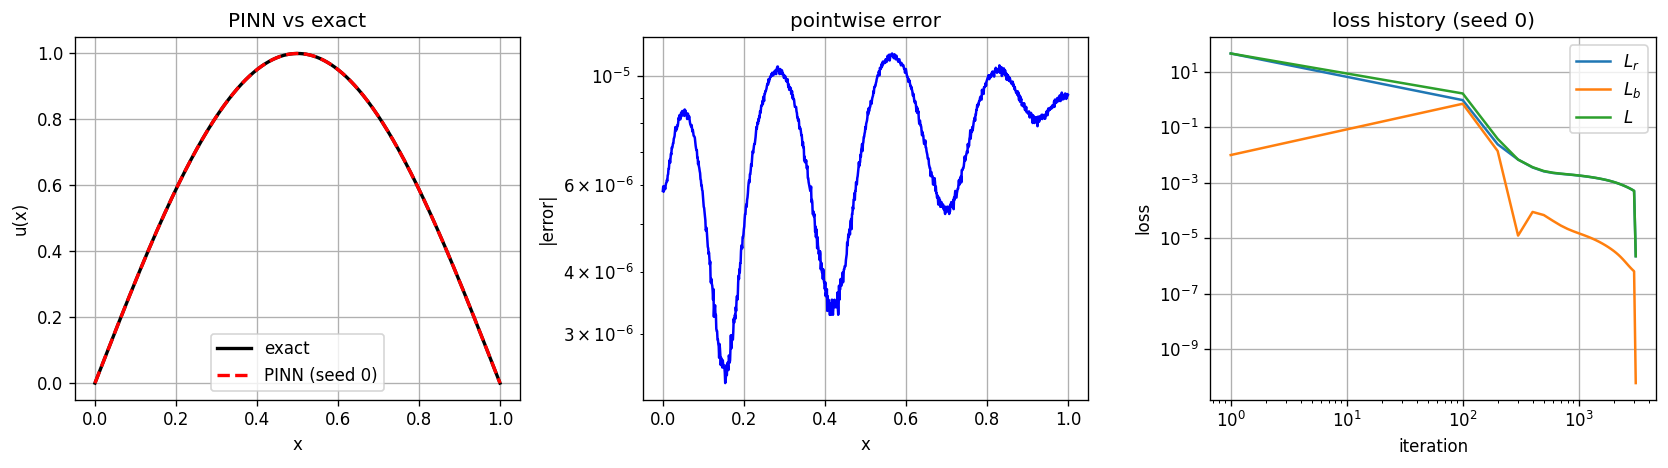

In [8]:
res, net, x_pinn, u_pinn, hist = full_runs[0]
exact = np.sin(PI * x_pinn)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(x_pinn, exact, "k-", lw=2, label="exact")
axes[0].plot(x_pinn, u_pinn, "r--", lw=2, label="PINN (seed 0)")
axes[0].set_xlabel("x"); axes[0].set_ylabel("u(x)")
axes[0].set_title("PINN vs exact"); axes[0].legend()

axes[1].semilogy(x_pinn, np.abs(u_pinn - exact) + 1e-16, "b-")
axes[1].set_xlabel("x"); axes[1].set_ylabel("|error|")
axes[1].set_title("pointwise error")

h = np.array(hist)
axes[2].loglog(h[:, 0], h[:, 1] + 1e-18, label=r"$L_r$")
axes[2].loglog(h[:, 0], h[:, 2] + 1e-18, label=r"$L_b$")
axes[2].loglog(h[:, 0], h[:, 3] + 1e-18, label=r"$L$")
axes[2].set_xlabel("iteration"); axes[2].set_ylabel("loss")
axes[2].set_title("loss history (seed 0)"); axes[2].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "A1组-6.1-图3-PINN结果.png", bbox_inches="tight")
plt.show()


## 6. 实验 B：遗漏边界与权重失衡

$\lambda_b=0$ 时只训练内部残差；$\lambda_b=10^{-4}$ 时边界项权重很小；$\lambda_b=100$ 时边界项被过度强调。另做一个受控反例：$u=x(1-x)N_\theta+3x+2$，只训练 $L_r$，其中仿射项对二阶导数没有贡献。

In [9]:
lam_values = [0.0, 1e-4, 1.0, 100.0]
lam_runs = {}
print(f"{'lambda_b':>10} {'L_r':>11} {'L_b':>11} {'total':>11} {'relL2':>11} {'bc':>11} {'time':>8}")
for lam in lam_values:
    run = full_runs[0] if lam == 1.0 else train(lam_b=lam, seed=0)
    lam_runs[lam] = run
    r = run[0]
    print(f"{lam:10.4g} {r['Lr_final']:11.4e} {r['Lb_final']:11.4e} "
          f"{r['loss_final']:11.4e} {r['rel_l2']:11.4e} {r['bc_err']:11.4e} {r['t_total']:8.2f}")
RESULTS["lam"] = {str(lam): lam_runs[lam][0] for lam in lam_values}

grad_rows = [grad_norm_ratio(lam) for lam in lam_values]
print()
print(f"{'lambda_b':>10} {'||grad L_r||':>14} {'||grad lambda_b L_b||':>22} {'ratio':>12}")
for g in grad_rows:
    ratio = "inf" if g["ratio"] is None else f"{g['ratio']:.3e}"
    print(f"{g['lam_b']:10.4g} {g['grad_r']:14.4e} {g['grad_b']:22.4e} {ratio:>12}")
RESULTS["grad"] = grad_rows

affine_run = train(lam_b=0.0, seed=0, hard=True, affine=(3.0, 2.0))
ra = affine_run[0]
print()
print("controlled affine: relL2 =", ra["rel_l2"], "max err =", ra["max_err"],
      "endpoints =", (ra["bc0"], ra["bc1"]), "L_b =", ra["Lb_final"])
assert abs(ra["bc0"] - 2.0) < 1e-4 and abs(ra["bc1"] - 5.0) < 1e-4
assert abs(ra["Lb_final"] - 14.5) < 1e-3
assert abs(ra["rel_l2"] - math.sqrt(26.0)) < 1e-2
print("PASS: 受控反例复现了 (2,5)、L_b=14.5 与相对误差 sqrt(26)")
RESULTS["affine"] = ra


  lambda_b         L_r         L_b       total       relL2          bc     time


         0  8.4355e-07  1.1374e+00  8.4355e-07  1.4142e+00  1.4200e+00     9.04


    0.0001  9.6284e-07  7.8655e-02  8.8284e-06  3.4292e-01  3.9372e-01     8.52
         1  2.2302e-06  5.8198e-11  2.2302e-06  1.0956e-05  9.2387e-06     9.51


       100  2.2807e-05  1.3185e-08  2.4125e-05  1.3362e-04  1.3296e-04     9.07

  lambda_b   ||grad L_r||  ||grad lambda_b L_b||        ratio
         0     1.3882e+01             0.0000e+00          inf
    0.0001     1.3882e+01             4.0945e-05    3.390e+05
         1     1.3882e+01             4.0945e-01    3.390e+01
       100     1.3882e+01             4.0945e+01    3.390e-01



controlled affine: relL2 = 5.101863384246826 max err = 5.0 endpoints = (2.0, 5.0) L_b = 14.5
PASS: 受控反例复现了 (2,5)、L_b=14.5 与相对误差 sqrt(26)


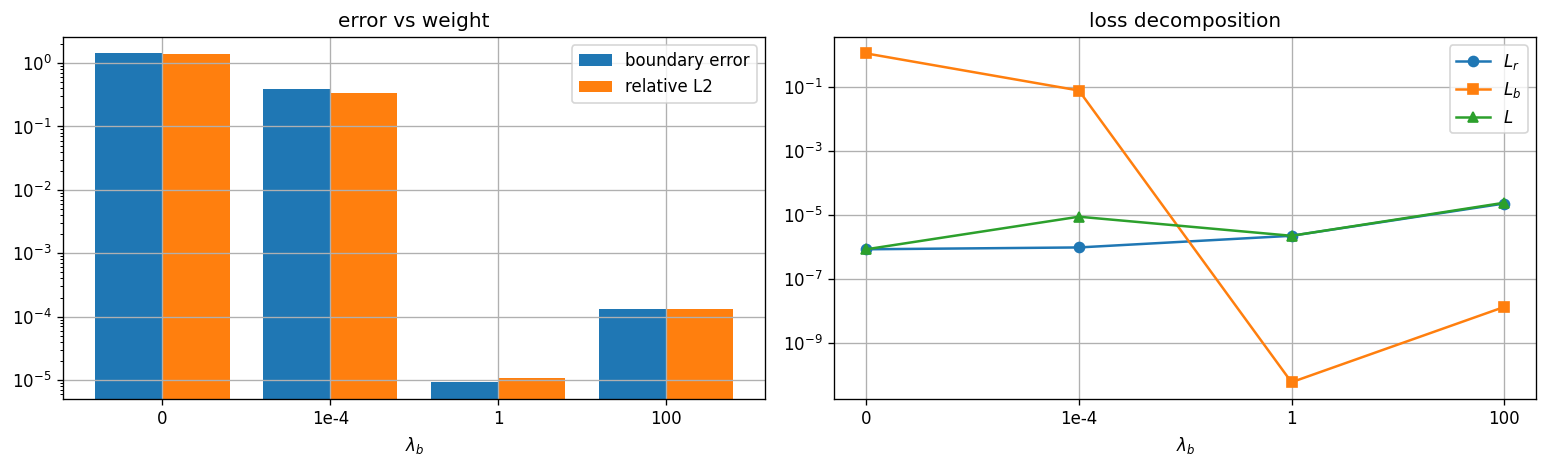

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
labels = ["0", "1e-4", "1", "100"]
xpos = np.arange(len(labels))
bc = np.array([lam_runs[lam][0]["bc_err"] for lam in lam_values])
rl2 = np.array([lam_runs[lam][0]["rel_l2"] for lam in lam_values])
axes[0].bar(xpos - 0.2, np.maximum(bc, 1e-16), 0.4, label="boundary error")
axes[0].bar(xpos + 0.2, np.maximum(rl2, 1e-16), 0.4, label="relative L2")
axes[0].set_yscale("log"); axes[0].set_xticks(xpos); axes[0].set_xticklabels(labels)
axes[0].set_xlabel(r"$\lambda_b$"); axes[0].set_title("error vs weight")
axes[0].legend()

Lr = np.array([lam_runs[lam][0]["Lr_final"] for lam in lam_values])
Lb = np.array([lam_runs[lam][0]["Lb_final"] for lam in lam_values])
tot = np.array([lam_runs[lam][0]["loss_final"] for lam in lam_values])
axes[1].plot(xpos, np.maximum(Lr, 1e-18), "o-", label=r"$L_r$")
axes[1].plot(xpos, np.maximum(Lb, 1e-18), "s-", label=r"$L_b$")
axes[1].plot(xpos, np.maximum(tot, 1e-18), "^-", label=r"$L$")
axes[1].set_yscale("log"); axes[1].set_xticks(xpos); axes[1].set_xticklabels(labels)
axes[1].set_xlabel(r"$\lambda_b$"); axes[1].set_title("loss decomposition")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "A1组-6.1-图4-权重扫描.png", bbox_inches="tight")
plt.show()


## 7. 实验 C：硬约束修复

对零 Dirichlet 边界，令 $u_\theta(x)=x(1-x)N_\theta(x)$，边界条件精确成立，损失只保留 $L_r$。预测：边界误差为 0，解误差与软约束同量级或更好。

hard: relL2 = 3.789552465605084e-06 max err = 5.125999450683594e-06 bc = 0.0 resRMS = 0.0014747801469638944 time = 11.971040899996297
PASS: 硬约束边界误差精确为 0


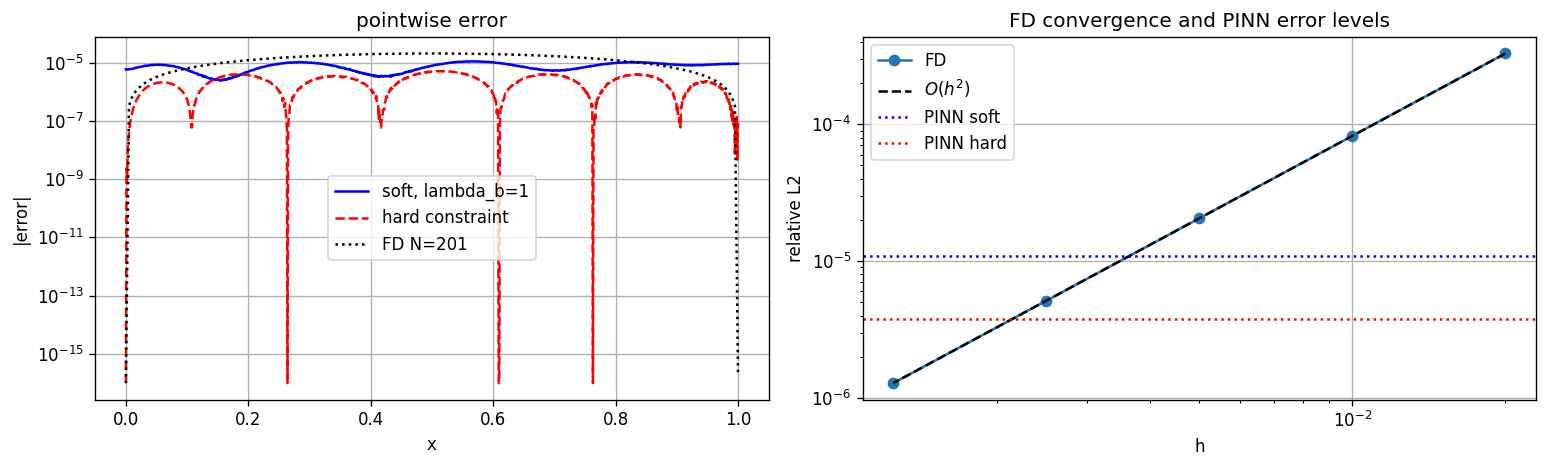

In [11]:
hard_run = train(lam_b=0.0, seed=0, hard=True)
rh = hard_run[0]
print("hard: relL2 =", rh["rel_l2"], "max err =", rh["max_err"],
      "bc =", rh["bc_err"], "resRMS =", rh["res_rms"], "time =", rh["t_total"])
assert rh["bc_err"] == 0.0
print("PASS: 硬约束边界误差精确为 0")
RESULTS["hard"] = rh

res_soft, _, x_soft, u_soft, _ = full_runs[0]
x_fd, u_fd, rel_fd, _ = fd_solve(201)
exact_soft = np.sin(PI * x_soft)
exact_fd = np.sin(PI * x_fd)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].semilogy(x_soft, np.abs(u_soft - exact_soft) + 1e-16, "b-", label="soft, lambda_b=1")
axes[0].semilogy(hard_run[2], np.abs(hard_run[3] - np.sin(PI * hard_run[2])) + 1e-16,
                 "r--", label="hard constraint")
axes[0].semilogy(x_fd, np.abs(u_fd - exact_fd) + 1e-16, "k:", label="FD N=201")
axes[0].set_xlabel("x"); axes[0].set_ylabel("|error|")
axes[0].set_title("pointwise error"); axes[0].legend()

h_fd = np.array([r["h"] for r in FD_ROWS])
e_fd = np.array([r["rel_l2"] for r in FD_ROWS])
axes[1].loglog(h_fd, e_fd, "o-", label="FD")
axes[1].loglog(h_fd, e_fd[-1] * (h_fd / h_fd[-1]) ** 2, "k--", label=r"$O(h^2)$")
axes[1].axhline(res_soft["rel_l2"], color="b", ls=":", label="PINN soft")
axes[1].axhline(rh["rel_l2"], color="r", ls=":", label="PINN hard")
axes[1].set_xlabel("h"); axes[1].set_ylabel("relative L2")
axes[1].set_title("FD convergence and PINN error levels"); axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "A1组-6.1-图5-硬约束与有限差分.png", bbox_inches="tight")
plt.show()


## 8. 实验 D：有限配点盲区

构造
$$p(x)=x^3(1-x)^3\prod_{i=1}^{6}(x-x_i)^3$$
并归一化。它在两个端点和 6 个配点上满足 $p=p'=p''=0$。取 $u_\varepsilon=u^*+\varepsilon p$，$\varepsilon=0.1$。这是解析构造，不是训练结果。

In [12]:
Nr = 6
xr_poly = ((torch.arange(Nr, dtype=torch.float64) + 0.5) / Nr).reshape(-1, 1)
x_dense = torch.linspace(0.0, 1.0, 4001, dtype=torch.float64).reshape(-1, 1)

def poly(x):
    p = x ** 3 * (1.0 - x) ** 3
    for xi in xr_poly:
        p = p * (x - xi) ** 3
    return p

def poly_derivs(x):
    x = x.clone().requires_grad_(True)
    p = poly(x)
    px = torch.autograd.grad(p, x, grad_outputs=torch.ones_like(p), create_graph=True)[0]
    pxx = torch.autograd.grad(px, x, grad_outputs=torch.ones_like(px), create_graph=False)[0]
    return p, px, pxx

p_raw, _, pxx_raw = poly_derivs(x_dense)
scale = float(p_raw.abs().max())
p = p_raw / scale
pxx = pxx_raw / scale
p_pts, _, pxx_pts = poly_derivs(xr_poly)
p_bc, _, pxx_bc = poly_derivs(torch.tensor([[0.0], [1.0]], dtype=torch.float64))
eps = 0.1
u_dense = torch.sin(PI * x_dense)
u_eps = u_dense + eps * p
r_dense = -eps * pxx
err_dense = u_eps - u_dense
poly_res = dict(Nr=Nr, eps=eps, p_max=float(p.abs().max()),
                p_at_points=float(p_pts.abs().max()),
                pxx_at_points=float(pxx_pts.abs().max()),
                p_at_bc=float(p_bc.abs().max()),
                pxx_at_bc=float(pxx_bc.abs().max()),
                u_max_err=float(err_dense.abs().max()),
                rel_l2=float(torch.linalg.norm(err_dense) / torch.linalg.norm(u_dense)),
                r_at_points=float((eps * pxx_pts).abs().max()),
                r_dense_max=float(r_dense.abs().max()),
                r_dense_rms=float(torch.sqrt((r_dense ** 2).mean())))
for k, v in poly_res.items():
    print(f"{k:16s} = {v}")
assert poly_res["p_at_points"] < 1e-12
assert poly_res["pxx_at_points"] < 1e-10
assert poly_res["p_at_bc"] < 1e-12
assert poly_res["u_max_err"] > 0.09
assert poly_res["r_dense_max"] > 1.0
print("PASS: 配点残差为零，但密网格残差与解误差非零")
RESULTS["poly"] = poly_res


Nr               = 6
eps              = 0.1
p_max            = 1.0
p_at_points      = 0.0
pxx_at_points    = 0.0
p_at_bc          = 0.0
pxx_at_bc        = 0.0
u_max_err        = 0.10000000000000002
rel_l2           = 0.05265344549580575
r_at_points      = 0.0
r_dense_max      = 569.2786613064372
r_dense_rms      = 115.72569000176651
PASS: 配点残差为零，但密网格残差与解误差非零


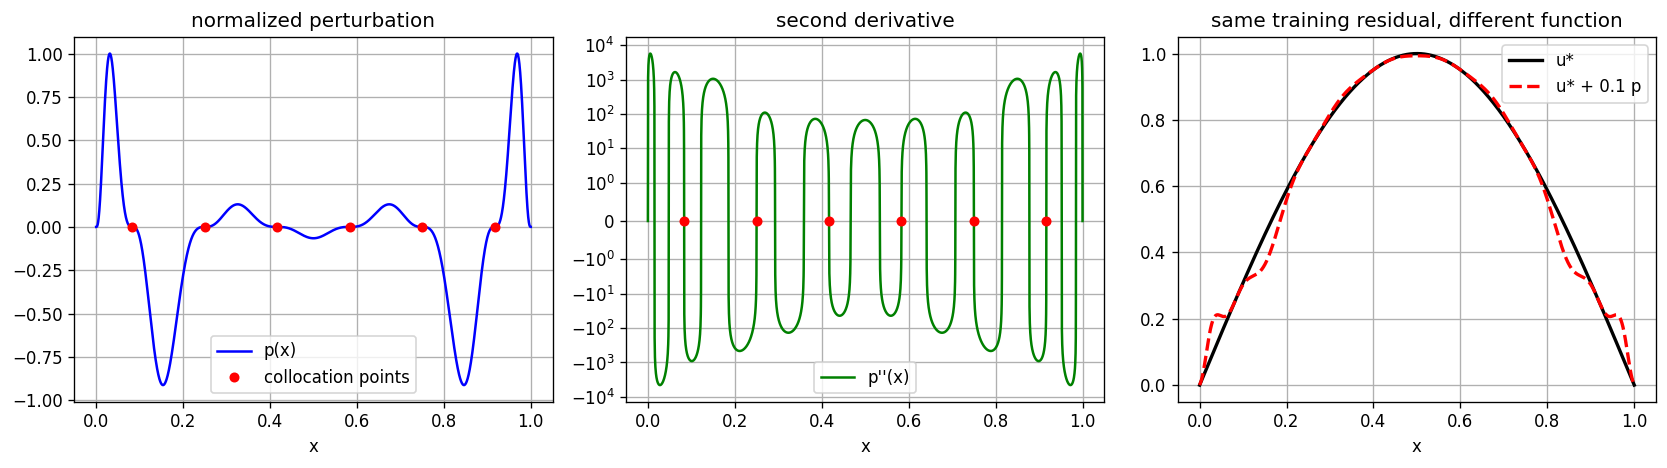

In [13]:
x_np = x_dense.detach().cpu().numpy().ravel()
p_np = p.detach().cpu().numpy().ravel()
pxx_np = pxx.detach().cpu().numpy().ravel()
u_np = u_dense.detach().cpu().numpy().ravel()
u_eps_np = u_eps.detach().cpu().numpy().ravel()
xp = xr_poly.detach().cpu().numpy().ravel()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(x_np, p_np, "b-", label="p(x)")
axes[0].plot(xp, np.zeros_like(xp), "ro", ms=5, label="collocation points")
axes[0].set_xlabel("x"); axes[0].set_title("normalized perturbation")
axes[0].legend()

axes[1].plot(x_np, pxx_np, "g-", label="p''(x)")
axes[1].plot(xp, np.zeros_like(xp), "ro", ms=5)
axes[1].set_yscale("symlog", linthresh=1.0)
axes[1].set_xlabel("x"); axes[1].set_title("second derivative")
axes[1].legend()

axes[2].plot(x_np, u_np, "k-", lw=2, label="u*")
axes[2].plot(x_np, u_eps_np, "r--", lw=2, label=r"u* + 0.1 p")
axes[2].set_xlabel("x"); axes[2].set_title("same training residual, different function")
axes[2].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "A1组-6.1-图6-有限配点.png", bbox_inches="tight")
plt.show()


## 9. 结果汇总与自检

In [14]:
rows = []
for r in RESULTS["full"]:
    rows.append(["完整损失", f"{r['lam_b']:g}", f"{r['seed']}", f"{r['rel_l2']:.3e}",
                 f"{r['bc_err']:.3e}", f"{r['res_rms']:.3e}", f"{r['t_total']:.2f}"])
for lam in lam_values:
    r = RESULTS["lam"][str(lam)]
    rows.append(["权重扫描", f"{lam:g}", "0", f"{r['rel_l2']:.3e}",
                 f"{r['bc_err']:.3e}", f"{r['res_rms']:.3e}", f"{r['t_total']:.2f}"])
for name, r in (("硬约束", RESULTS["hard"]), ("受控反例", RESULTS["affine"])):
    rows.append([name, "-", "0", f"{r['rel_l2']:.3e}", f"{r['bc_err']:.3e}",
                 f"{r['res_rms']:.3e}", f"{r['t_total']:.2f}"])
header = "| 实验 | lambda_b | seed | rel L2 | 边界误差 | 独立残差 RMS | 时间/s |\n|---|---|---|---|---|---|---|\n"
display(Markdown(header + "\n".join("| " + " | ".join(row) + " |" for row in rows)))

checks = {
    "autograd 二阶导数": RESULTS["autograd"]["err"] < 1e-12,
    "FD 观测阶": all(1.9 < o < 2.1 for o in orders[-2:]),
    "完整损失 relL2<1e-3": all(r["rel_l2"] < 1e-3 for r in RESULTS["full"]),
    "完整损失 边界<1e-3": all(r["bc_err"] < 1e-3 for r in RESULTS["full"]),
    "硬约束 边界=0": RESULTS["hard"]["bc_err"] == 0.0,
    "受控反例 relL2≈sqrt(26)": abs(RESULTS["affine"]["rel_l2"] - math.sqrt(26.0)) < 1e-2,
    "有限配点 点残差=0": RESULTS["poly"]["r_at_points"] < 1e-12,
    "有限配点 密网格残差>1": RESULTS["poly"]["r_dense_max"] > 1.0,
}
print()
for k, v in checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
print()
print("total training time (s):", sum(r["t_total"] for r in RESULTS["full"])
      + sum(RESULTS["lam"][str(lam)]["t_total"] for lam in lam_values if lam != 1.0)
      + RESULTS["hard"]["t_total"] + RESULTS["affine"]["t_total"])
print()
print(json.dumps(RESULTS, ensure_ascii=False, indent=2, allow_nan=False))


| 实验 | lambda_b | seed | rel L2 | 边界误差 | 独立残差 RMS | 时间/s |
|---|---|---|---|---|---|---|
| 完整损失 | 1 | 0 | 1.096e-05 | 9.239e-06 | 1.508e-03 | 9.51 |
| 完整损失 | 1 | 1 | 1.353e-05 | 1.276e-05 | 3.816e-03 | 8.45 |
| 权重扫描 | 0 | 0 | 1.414e+00 | 1.420e+00 | 9.360e-04 | 9.04 |
| 权重扫描 | 0.0001 | 0 | 3.429e-01 | 3.937e-01 | 9.979e-04 | 8.52 |
| 权重扫描 | 1 | 0 | 1.096e-05 | 9.239e-06 | 1.508e-03 | 9.51 |
| 权重扫描 | 100 | 0 | 1.336e-04 | 1.330e-04 | 4.847e-03 | 9.07 |
| 硬约束 | - | 0 | 3.790e-06 | 0.000e+00 | 1.475e-03 | 11.97 |
| 受控反例 | - | 0 | 5.102e+00 | 5.000e+00 | 1.475e-03 | 11.78 |


PASS  autograd 二阶导数
PASS  FD 观测阶
PASS  完整损失 relL2<1e-3
PASS  完整损失 边界<1e-3
PASS  硬约束 边界=0
PASS  受控反例 relL2≈sqrt(26)
PASS  有限配点 点残差=0
PASS  有限配点 密网格残差>1

total training time (s): 68.33559199999581

{
  "counterexample": {
    "residual_max": 1.7763568394002505e-15,
    "v0": 2.0,
    "v1": 5.0,
    "Lb": 14.5,
    "rel_l2": 5.0990195135927845,
    "rel_l2_grid": 5.100441230913262
  },
  "autograd": {
    "u_xx": -7.984677688239065,
    "exact": -7.984677688239065,
    "err": 0.0
  },
  "fd": [
    {
      "n": 51,
      "h": 0.02,
      "rel_l2": 0.00032905176293594935,
      "max_err": 0.0003290517629355172,
      "order": null
    },
    {
      "n": 101,
      "h": 0.01,
      "rel_l2": 8.22507622119642e-05,
      "max_err": 8.225076221179961e-05,
      "order": 2.000213597931912
    },
    {
      "n": 201,
      "h": 0.005,
      "rel_l2": 2.05619295258926e-05,
      "max_err": 2.0561929529927525e-05,
      "order": 2.0000533952663364
    },
    {
      "n": 401,
      "h": 0.0025,